<a href="https://colab.research.google.com/github/siojzz/UTSDEEPLEARNING/blob/task3-representasi/kode/task3_cluster/task3_representasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3 — Tahap 1: Representasi Tanpa Label dan Fusi Dua Modalitas

**Ruang lingkup.** Task 3 mengelompokkan 36.000 sampel material dari laboratorium fiktif yang tidak berlabel. Setiap sampel memiliki citra mikrostruktur 64×64 (`gambar`) dan spektrum komposisi 128 dimensi (`spektrum`), serta keterangan mikroskop yang dipakai (M1 atau M2). Notebook ini adalah **tahap pertama**: membangun representasi yang layak dikelompokkan. Pengelompokan itu sendiri (K-Means, GMM, jumlah klaster, DEC) dikerjakan pada tahap berikutnya dan memakai berkas embedding yang dihasilkan di sini.

**Pertanyaan yang dijawab.**
1. Apakah mikroskop memengaruhi data sehingga dapat mengacaukan klaster? Kolom `mikroskop` adalah keterangan alat, bukan label kelas. Klaster yang hanya memisahkan M1 dari M2 akan menyesatkan.
2. Representasi apa yang dapat dipelajari tanpa label dari tiap modalitas (*autoencoder* peredam derau dan SimCLR untuk gambar, *autoencoder* untuk spektrum)?
3. Bagaimana kedua modalitas digabung (penggabungan embedding dan *autoencoder* gabungan dengan *modality dropout*)?
4. Tanpa label, bagaimana representasi diperiksa sebelum dikelompokkan?

**Alur.** 0 Persiapan → 1 Data → 2 Efek mikroskop → 3 Pembanding PCA → 4 Encoder gambar → 5 Encoder spektrum → 6 Fusi → 7 Pemeriksaan tanpa label → 8 Penyimpanan dan serah-terima → 9 Kesimpulan → 10 Commit.

## 0. Persiapan lingkungan dan data

Pelatihan memerlukan GPU (T4, L4, atau G4). Identitas akun GitHub pemilik pekerjaan ini diisi pada sel pertama, dan seluruh hiperparameter dikumpulkan di satu tempat agar mudah ditelusuri.

In [2]:
AKUN_GITHUB = 'siojzz'
EMAIL_GITHUB = 'sfyrian21@gmail.com'

# Hiperparameter (dikumpulkan di sini)
SEED = 0
D_G, D_S, D_F = 64, 32, 64            # dimensi embedding: gambar, spektrum, fusi gabungan
EP_AE_G, EP_SIMCLR, EP_AE_S, EP_JOINT = 40, 60, 60, 40
BS, BS_SIMCLR = 256, 512
RUN_SIMCLR = True

import torch, numpy, pandas, sklearn, sys, warnings, time, json, os
warnings.filterwarnings('ignore')
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", numpy.__version__,
      "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)
print("GPU tersedia:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Aktifkan GPU dulu: Runtime -> Change runtime type -> T4 GPU"
dev = 'cuda'

Python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
GPU tersedia: True


In [3]:
if not os.path.exists('/content/data/clustering.npz'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
!ls /content/data

Downloading...
From (original): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb
From (redirected): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb&confirm=t&uuid=ebbe867e-d271-453d-8024-fe48f91a52ec
To: /content/data_uts_dl.zip
100% 396M/396M [00:05<00:00, 72.7MB/s]
clustering_meta.csv  klasifikasi_test_meta.csv	 klasifikasi_train.npz
clustering.npz	     klasifikasi_test.npz	 rul_test.csv.gz
kamus_data.md	     klasifikasi_train_meta.csv  rul_train.csv.gz


In [4]:
from google.colab import userdata
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/{AKUN_GITHUB}/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "{AKUN_GITHUB}"
!git config user.email "{EMAIL_GITHUB}"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git pull --no-edit upstream main
!git checkout -B task3-representasi
!mkdir -p kode/task3_cluster/emb kode/task3_cluster/hasil kode/task3_cluster/bobot
!ls kode

Cloning into '/content/UTSDEEPLEARNING'...
remote: Enumerating objects: 163, done.
remote: Counting objects: 100% (55/55), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 163 (delta 11), reused 25 (delta 2), pack-reused 108 (from 1)
Receiving objects: 100% (163/163), 11.27 MiB | 30.45 MiB/s, done.
Resolving deltas: 100% (46/46), done.
/content/UTSDEEPLEARNING
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> upstream/main
Already up to date.
Switched to a new branch 'task3-representasi'
README.md  task1_klasifikasi  task2_rul  task3_cluster


### Kode pendukung

Dua berkas ditulis ke `kode/task3_cluster/` agar dapat dipakai ulang oleh tahap berikutnya.

| Berkas | Isi |
|---|---|
| `clu_data.py` | pemuatan data, normalisasi (global atau per mikroskop), diagnostik tanpa label: tebakan mikroskop dari representasi, silhouette per jumlah klaster, irisan tetangga terdekat antar modalitas, penggabungan embedding |
| `clu_model.py` | *autoencoder* gambar, SimCLR, *autoencoder* spektrum, *autoencoder* gabungan dengan *modality dropout*, serta fungsi pelatihan dan ekstraksi embedding |

In [5]:
%%writefile /content/UTSDEEPLEARNING/kode/task3_cluster/clu_data.py
"""Pemuatan, normalisasi, dan diagnostik tanpa label untuk Task 3 (clustering).
Hanya numpy, pandas, dan scikit-learn; tidak memakai PyTorch."""
import numpy as np, pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, balanced_accuracy_score, silhouette_score
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

DATA = '/content/data'


def muat(folder=DATA):
    z = np.load(f'{folder}/clustering.npz')
    g, s = z['gambar'], z['spektrum'].astype(np.float32)
    meta = pd.read_csv(f'{folder}/clustering_meta.csv')
    if 'indeks' in meta.columns:
        meta = meta.sort_values('indeks').reset_index(drop=True)
    assert len(meta) == len(g) == len(s), (len(meta), len(g), len(s))
    return g, s, meta


def isi_spektrum(s):
    """Isi NaN/inf dengan median per fitur. Mengembalikan (spektrum, jumlah sel diisi)."""
    s = np.array(s, dtype=np.float32, copy=True)
    s[~np.isfinite(s)] = np.nan
    n_isi = int(np.isnan(s).sum())
    if n_isi:
        med = np.nanmedian(s, axis=0)
        med = np.where(np.isfinite(med), med, 0.0)
        idx = np.where(np.isnan(s))
        s[idx] = med[idx[1]]
    return s, n_isi


def siapkan(g, s, mik, per_mikroskop=True):
    """Gambar -> [0,1] lalu z-score skalar; spektrum -> z-score per fitur.
    per_mikroskop=True: statistik dihitung terpisah untuk tiap mikroskop."""
    g = g.astype(np.float32) / 255.0
    s, _ = isi_spektrum(s)
    mik = np.asarray(mik)
    gn, sn = np.empty_like(g), np.empty_like(s)
    grup = [mik == m for m in np.unique(mik)] if per_mikroskop else [np.ones(len(g), bool)]
    for idx in grup:
        gn[idx] = (g[idx] - g[idx].mean()) / (g[idx].std() + 1e-6)
        sn[idx] = (s[idx] - s[idx].mean(0)) / (s[idx].std(0) + 1e-6)
    return gn, sn


def ringkas(g, s, meta):
    mik = meta['mikroskop'].astype(str)
    out = dict(n=int(len(g)), bentuk_gambar=list(g.shape), bentuk_spektrum=list(s.shape),
               dtype_gambar=str(g.dtype), gambar_min=int(g.min()), gambar_maks=int(g.max()),
               spektrum_nan=int((~np.isfinite(s)).sum()),
               id_unik=bool(meta['id_sampel'].is_unique),
               jumlah_mikroskop={k: int(v) for k, v in mik.value_counts().items()})
    st = {}
    for m in sorted(mik.unique()):
        i = (mik == m).values
        gm = g[i].astype(np.float32)
        sp = np.where(np.isfinite(s[i]), s[i], np.nan).astype(np.float64)
        st[m] = dict(gambar_rerata=float(gm.mean()), gambar_simpangan=float(gm.std()),
                     spektrum_rerata=float(np.nanmean(sp)), spektrum_simpangan=float(np.nanstd(sp)))
    out['per_mikroskop'] = st
    return out


def pca_baris(x, d, seed=0):
    x = x.reshape(len(x), -1)
    return PCA(d, svd_solver='randomized', random_state=seed).fit_transform(x).astype(np.float32)


def probe_mikroskop(emb, mik, cv=3, n_maks=15000, seed=0):
    """Seberapa mudah mikroskop ditebak dari representasi (regresi logistik linear, validasi silang)."""
    mik = np.asarray(mik).astype(str)
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(emb), min(n_maks, len(emb)), replace=False)
    x, y = StandardScaler().fit_transform(emb[idx]), mik[idx]
    clf = LogisticRegression(max_iter=300, class_weight='balanced')
    p = cross_val_predict(clf, x, y, cv=StratifiedKFold(cv, shuffle=True, random_state=seed))
    _, c = np.unique(y, return_counts=True)
    return dict(akurasi=float(accuracy_score(y, p)), akurasi_seimbang=float(balanced_accuracy_score(y, p)),
                mayoritas=float(c.max() / c.sum()))


def silhouette_k(emb, ks=range(2, 11), n=5000, seed=0):
    rng = np.random.RandomState(seed)
    x = emb[rng.choice(len(emb), min(n, len(emb)), replace=False)]
    return {int(k): float(silhouette_score(x, KMeans(k, n_init=3, random_state=seed).fit_predict(x))) for k in ks}


def tumpang_knn(a, b, k=10, n=6000, seed=0):
    """Rerata irisan k tetangga terdekat antara dua representasi (0..1), beserta nilai kebetulan."""
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(a), min(n, len(a)), replace=False)
    def tet(x):
        return NearestNeighbors(n_neighbors=k + 1).fit(x[idx]).kneighbors(x[idx], return_distance=False)[:, 1:]
    na, nb = tet(a), tet(b)
    irisan = (na[:, :, None] == nb[:, None, :]).any(2).sum(1) / k
    return dict(tumpang=float(irisan.mean()), kebetulan=float(k / (len(idx) - 1)))


def fusi_concat(eg, es):
    """Gabung dua embedding; tiap blok di-z-score per dimensi lalu dibagi sqrt(dimensi),
    sehingga kedua modalitas punya total varians sama."""
    def blok(e):
        e = (e - e.mean(0)) / (e.std(0) + 1e-6)
        return e / np.sqrt(e.shape[1])
    return np.concatenate([blok(eg), blok(es)], 1).astype(np.float32)


def simpan_emb(folder, nama, arr):
    arr = np.asarray(arr, dtype=np.float32)
    assert np.isfinite(arr).all() and np.abs(arr).max() < 6e4, nama
    np.save(f'{folder}/{nama}.npy', arr.astype(np.float16))


Writing /content/UTSDEEPLEARNING/kode/task3_cluster/clu_data.py


In [6]:
%%writefile /content/UTSDEEPLEARNING/kode/task3_cluster/clu_model.py
"""Model representasi tanpa label untuk Task 3: autoencoder gambar, SimCLR gambar,
autoencoder spektrum, dan autoencoder gabungan (fusi tingkat fitur dengan modality dropout)."""
import math, numpy as np, torch, torch.nn as nn, torch.nn.functional as F


def atur_seed(seed):
    np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


# ---------- gambar ----------
def _blok(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, stride=2, padding=1), nn.BatchNorm2d(o), nn.GELU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.GELU())


def _naik(i, o):
    return nn.Sequential(nn.ConvTranspose2d(i, o, 4, stride=2, padding=1), nn.BatchNorm2d(o), nn.GELU())


class EncGambar(nn.Module):
    def __init__(self, d=64):
        super().__init__()
        self.f = nn.Sequential(_blok(1, 32), _blok(32, 64), _blok(64, 128), _blok(128, 256))  # 64 -> 4
        self.fc = nn.Linear(256 * 4 * 4, d)

    def forward(self, x):          # x: (B,1,64,64)
        return self.fc(self.f(x).flatten(1))


class DecGambar(nn.Module):
    def __init__(self, d=64):
        super().__init__()
        self.fc = nn.Linear(d, 256 * 4 * 4)
        self.g = nn.Sequential(_naik(256, 128), _naik(128, 64), _naik(64, 32), _naik(32, 16),
                               nn.Conv2d(16, 1, 3, padding=1))

    def forward(self, z):
        return self.g(self.fc(z).view(-1, 256, 4, 4))


class AEGambar(nn.Module):
    def __init__(self, d=64):
        super().__init__()
        self.enc, self.dec = EncGambar(d), DecGambar(d)

    def forward(self, x):
        return self.dec(self.enc(x))


class SimCLR(nn.Module):
    def __init__(self, d=64):
        super().__init__()
        self.enc = EncGambar(d)
        self.proj = nn.Sequential(nn.GELU(), nn.Linear(d, 128), nn.GELU(), nn.Linear(128, 64))

    def forward(self, x):
        return F.normalize(self.proj(self.enc(x)), dim=1)


def nt_xent(z1, z2, tau=0.2):
    n = z1.shape[0]
    z = torch.cat([z1, z2])
    sim = z @ z.t() / tau
    sim = sim.masked_fill(torch.eye(2 * n, dtype=torch.bool, device=z.device), -1e9)
    tgt = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return F.cross_entropy(sim, tgt)


def aug_foto(x, kuat=1.0):
    """Kecerlangan, kontras, dan derau (meniru perbedaan akuisisi). x: (B,1,H,W)."""
    B, d = x.shape[0], x.device
    c = 1 + (torch.rand(B, 1, 1, 1, device=d) - 0.5) * 0.4 * kuat
    b = (torch.rand(B, 1, 1, 1, device=d) - 0.5) * 0.4 * kuat
    return x * c + b + torch.randn_like(x) * 0.05 * kuat


def aug_geo(x, rot=15.0, skala=0.3, geser=0.2):
    """Rotasi kecil, skala, pergeseran, dan cermin horizontal acak."""
    B, d = x.shape[0], x.device
    ang = (torch.rand(B, device=d) - 0.5) * 2 * math.radians(rot)
    sc = 1 + (torch.rand(B, device=d) - 0.5) * skala
    tx = (torch.rand(B, device=d) - 0.5) * geser
    ty = (torch.rand(B, device=d) - 0.5) * geser
    flip = (torch.rand(B, device=d) < 0.5).float() * 2 - 1
    cs, sn = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cs * flip, -sn, tx], 1), torch.stack([sn * flip, cs, ty], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)


# ---------- spektrum ----------
class EncSpektrum(nn.Module):
    def __init__(self, d=32, in_dim=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, 256), nn.GELU(), nn.Linear(256, 128), nn.GELU(), nn.Linear(128, d))

    def forward(self, x):
        return self.net(x)


class DecSpektrum(nn.Module):
    def __init__(self, d=32, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 128), nn.GELU(), nn.Linear(128, 256), nn.GELU(), nn.Linear(256, out_dim))

    def forward(self, z):
        return self.net(z)


class AESpektrum(nn.Module):
    def __init__(self, d=32):
        super().__init__()
        self.enc, self.dec = EncSpektrum(d), DecSpektrum(d)

    def forward(self, x):
        return self.dec(self.enc(x))


# ---------- gabungan ----------
class AEGabungan(nn.Module):
    """Dua encoder -> fusi tingkat fitur -> kode bersama z -> dua dekoder.
    Modality dropout mematikan salah satu modalitas secara acak saat pelatihan."""
    def __init__(self, d=64, h=128):
        super().__init__()
        self.eg, self.es = EncGambar(h), EncSpektrum(h)
        self.fuse = nn.Sequential(nn.GELU(), nn.Linear(2 * h, 128), nn.GELU(), nn.Linear(128, d))
        self.dg, self.ds = DecGambar(d), DecSpektrum(d)

    def encode(self, g, s, p_drop=0.0):
        hg, hs = self.eg(g), self.es(s)
        if self.training and p_drop > 0:
            r = torch.rand(hg.shape[0], 1, device=hg.device)
            hg = hg * (r >= p_drop / 2).float()                      # gambar dimatikan bila r < p/2
            hs = hs * ((r < p_drop / 2) | (r >= p_drop)).float()     # spektrum dimatikan bila p/2 <= r < p
        return self.fuse(torch.cat([hg, hs], 1))

    def decode(self, z):
        return self.dg(z), self.ds(z)


# ---------- pelatihan umum ----------
def latih(model, data, langkah, epoch, bs, lr, wd=1e-4, val_frac=0.1, seed=0, cetak=5, nama=''):
    """data: daftar tensor di GPU (dimensi pertama = sampel). langkah(model, *batch) -> loss."""
    atur_seed(seed)
    n = data[0].shape[0]
    dev = data[0].device
    perm = torch.randperm(n, device=dev)
    nv = int(n * val_frac)
    iv, it = perm[:nv], perm[nv:]
    spe = max(1, len(it) // bs)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epoch * spe)
    riwayat = []
    for ep in range(1, epoch + 1):
        model.train()
        p = it[torch.randperm(len(it), device=dev)]
        tr = 0.0
        for i in range(spe):
            b = p[i * bs:(i + 1) * bs]
            loss = langkah(model, *[t[b] for t in data])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); sch.step()
            tr += loss.item()
        model.eval()
        with torch.no_grad():
            va = float(np.mean([langkah(model, *[t[iv[j:j + 1024]] for t in data]).item()
                                for j in range(0, nv, 1024)]))
        riwayat.append((tr / spe, va))
        if ep == 1 or ep % cetak == 0 or ep == epoch:
            print(f"  {nama} ep {ep}/{epoch}: loss latih {tr / spe:.4f} | validasi {va:.4f}")
    return riwayat


@torch.no_grad()
def ekstrak(fn, data, bs=2048):
    """fn(*batch) -> embedding. Mengembalikan array numpy float32."""
    out = []
    for i in range(0, data[0].shape[0], bs):
        out.append(fn(*[t[i:i + bs] for t in data]).float().cpu())
    return torch.cat(out).numpy()


# ---------- fungsi langkah ----------
def langkah_ae_gambar(m, g):
    x = g.unsqueeze(1)
    return F.mse_loss(m(aug_foto(x, 0.5)), x)


def langkah_simclr(m, g):
    x = g.unsqueeze(1)
    v1, v2 = aug_foto(aug_geo(x), 1.0), aug_foto(aug_geo(x), 1.0)
    return nt_xent(m(v1), m(v2))


def langkah_ae_spektrum(m, s):
    return F.mse_loss(m(s + 0.1 * torch.randn_like(s)), s)


def langkah_gabungan(m, g, s):
    x = g.unsqueeze(1)
    z = m.encode(aug_foto(x, 0.5), s + 0.1 * torch.randn_like(s), p_drop=0.3)
    rg, rs = m.decode(z)
    return F.mse_loss(rg, x) + F.mse_loss(rs, s)


Writing /content/UTSDEEPLEARNING/kode/task3_cluster/clu_model.py


In [7]:
import sys
sys.path.insert(0, '/content/UTSDEEPLEARNING/kode/task3_cluster')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import importlib, clu_data, clu_model
importlib.reload(clu_data); importlib.reload(clu_model)
from clu_data import *
from clu_model import *
OUT = '/content/UTSDEEPLEARNING/kode/task3_cluster'
INFO, HASIL = {}, {}

## 1. Data

Pemeriksaan pertama: bentuk dan tipe data, nilai hilang, keunikan ID, dan jumlah sampel per mikroskop. Urutan baris pada `clustering_meta.csv` harus sama dengan urutan pada `clustering.npz`, karena seluruh keluaran tahap ini diindeks berdasarkan urutan itu.

In [8]:
g_raw, s_raw, meta = muat()
mik = meta['mikroskop'].astype(str).values
print(meta.head(3).to_string())
INFO['data'] = ringkas(g_raw, s_raw, meta)
for k, v in INFO['data'].items():
    if k != 'per_mikroskop': print(f"{k}: {v}")
print(pd.DataFrame(INFO['data']['per_mikroskop']).T.round(3))

   indeks id_sampel mikroskop
0       0   S966119        M1
1       1   S315633        M2
2       2   S805122        M1
n: 36000
bentuk_gambar: [36000, 64, 64]
bentuk_spektrum: [36000, 128]
dtype_gambar: uint8
gambar_min: 0
gambar_maks: 255
spektrum_nan: 0
id_unik: True
jumlah_mikroskop: {'M1': 21636, 'M2': 14364}
    gambar_rerata  gambar_simpangan  spektrum_rerata  spektrum_simpangan
M1        127.795            23.714            0.449               0.406
M2        146.068            23.221            0.447               0.408


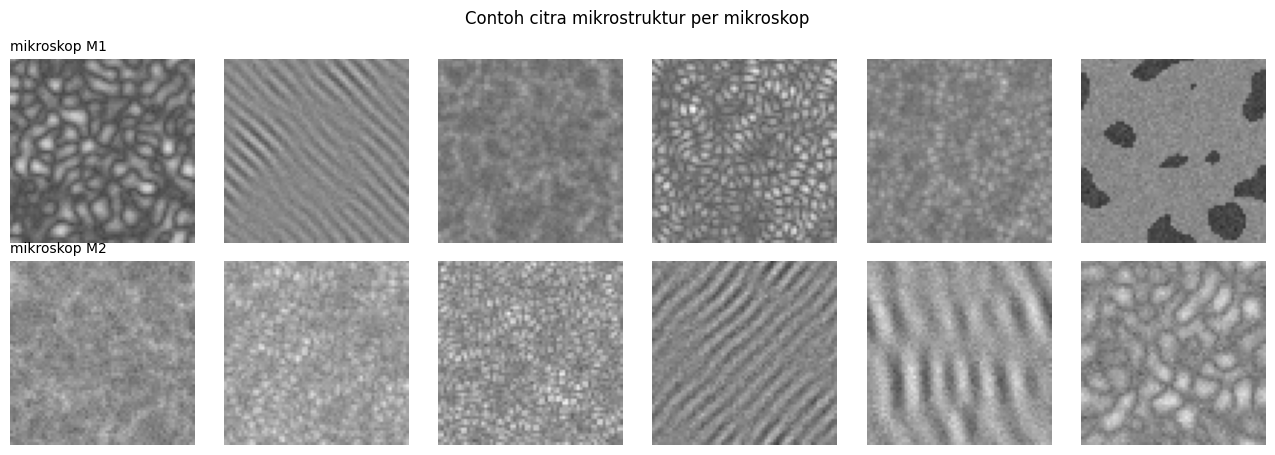

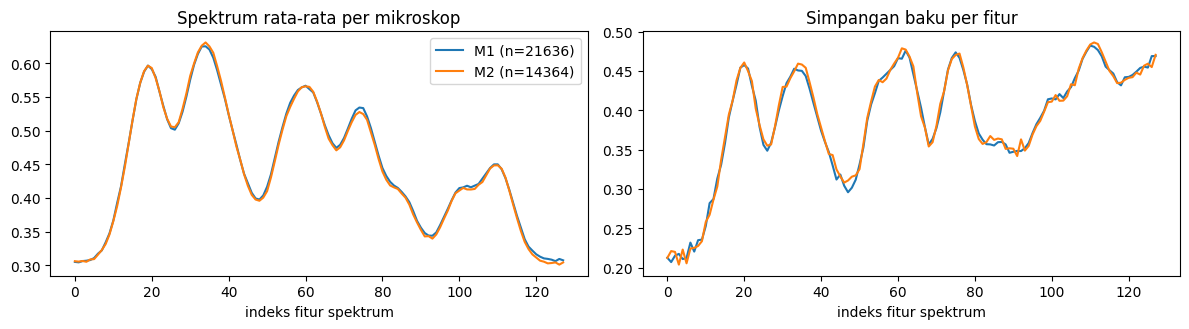

sel spektrum yang diisi median: 0


In [9]:
fig, ax = plt.subplots(2, 6, figsize=(13, 4.6))
rng = np.random.RandomState(1)
for r, m in enumerate(sorted(np.unique(mik))[:2]):
    idx = rng.choice(np.where(mik == m)[0], 6, replace=False)
    for c, i in enumerate(idx):
        ax[r, c].imshow(g_raw[i], cmap='gray', vmin=0, vmax=255); ax[r, c].axis('off')
    ax[r, 0].set_title(f"mikroskop {m}", loc='left', fontsize=10)
plt.suptitle("Contoh citra mikrostruktur per mikroskop"); plt.tight_layout(); plt.show()

s_fill, n_isi = isi_spektrum(s_raw)
INFO['spektrum_diisi'] = n_isi
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for m in sorted(np.unique(mik)):
    i = mik == m
    ax[0].plot(s_fill[i].mean(0), label=f"{m} (n={i.sum()})")
    ax[1].plot(s_fill[i].std(0), label=m)
ax[0].set_title("Spektrum rata-rata per mikroskop"); ax[1].set_title("Simpangan baku per fitur"); ax[0].legend()
for a in ax: a.set_xlabel("indeks fitur spektrum")
plt.tight_layout(); plt.show()
print("sel spektrum yang diisi median:", n_isi)

## 2. Efek mikroskop

Dua mikroskop dapat menghasilkan citra dengan kecerlangan dan kontras berbeda dan spektrum dengan sedikit pergeseran, meskipun materialnya sama. Agar klaster mencerminkan material dan bukan alat, diperiksa seberapa mudah **mikroskop ditebak** dari fitur mentah memakai regresi logistik linear (PCA 32 dimensi, validasi silang 3 lipatan). Akurasi seimbang sekitar 0,5 berarti mikroskop tidak dapat dibedakan (nilai sedikit di bawah 0,5 dapat muncul sebagai artefak validasi silang pada data yang sudah dipusatkan per mikroskop, dan dibaca sama dengan 0,5). Dibandingkan dua perlakuan:

- **Normalisasi global**: satu rerata dan simpangan baku untuk seluruh data.
- **Normalisasi per mikroskop**: gambar distandarkan per mikroskop (kecerlangan dan kontras), spektrum distandarkan per fitur per mikroskop. Cara ini serupa dengan normalisasi per lini pada Task 1.

Normalisasi per mikroskop dipakai bila mikroskop dapat ditebak dari fitur mentah (akurasi seimbang di atas 0,55). Catatan asumsi: bila komposisi material kedua mikroskop sebenarnya berbeda, normalisasi ini ikut menghapus sebagian perbedaan itu. Keputusan akhir dan batasannya dilaporkan di kesimpulan.

,normalisasi,modalitas,akurasi,akurasi_seimbang,mayoritas
0,global,gambar,0.784,0.786,0.601
1,global,spektrum,0.494,0.490,0.601
2,per mikroskop,gambar,0.506,0.505,0.601
3,per mikroskop,spektrum,0.493,0.489,0.601


keputusan: normalisasi per mikroskop | waktu 24 dtk


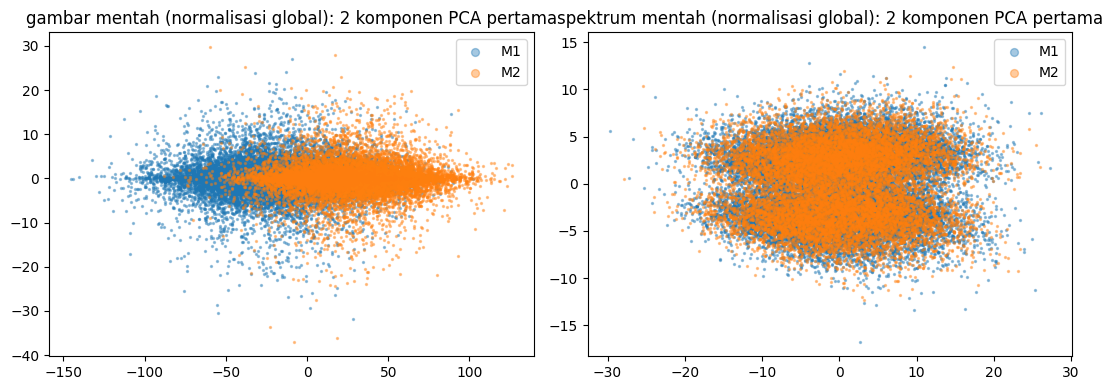

In [10]:
t0 = time.time()
pil = {}
fitur = {}
for nama, pm in [('global', False), ('per mikroskop', True)]:
    gn_, sn_ = siapkan(g_raw, s_raw, mik, per_mikroskop=pm)
    pil[nama] = (gn_, sn_)
    fitur[nama] = (pca_baris(gn_, 32, SEED), pca_baris(sn_, 32, SEED))
baris = []
for nama in pil:
    for mod, f in zip(['gambar', 'spektrum'], fitur[nama]):
        p = probe_mikroskop(f, mik, seed=SEED)
        baris.append(dict(normalisasi=nama, modalitas=mod, akurasi=p['akurasi'], akurasi_seimbang=p['akurasi_seimbang'], mayoritas=p['mayoritas']))
tab_mik = pd.DataFrame(baris)
display(tab_mik.round(3))
NORM_PER_MIK = bool((tab_mik[tab_mik.normalisasi == 'global'].akurasi_seimbang > 0.55).any())
pilih = 'per mikroskop' if NORM_PER_MIK else 'global'
gn, sn = pil[pilih]
del pil
INFO['mikroskop'] = dict(tabel=baris, per_mikroskop_dipakai=NORM_PER_MIK)
print(f"keputusan: normalisasi {pilih} | waktu {time.time() - t0:.0f} dtk")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (mod, f) in zip(ax, zip(['gambar', 'spektrum'], fitur['global'])):
    for m in sorted(np.unique(mik)):
        a.scatter(f[mik == m, 0], f[mik == m, 1], s=2, alpha=0.4, label=m)
    a.set_title(f"{mod} mentah (normalisasi global): 2 komponen PCA pertama"); a.legend(markerscale=4)
plt.tight_layout(); plt.show()

## 3. Pembanding PCA

PCA pada data yang sudah dinormalisasi menjadi pembanding non-*deep-learning*: embedding yang dipelajari harus lebih baik daripada ini agar pantas dipakai. Gambar diproyeksikan ke 64 dimensi dan spektrum ke 32 dimensi, lalu digabung dengan bobot yang sama antar modalitas.

In [11]:
EMB = {}
EMB['pca_gambar'] = pca_baris(gn, D_G, SEED)
EMB['pca_spektrum'] = pca_baris(sn, D_S, SEED)
EMB['pca_fusi'] = fusi_concat(EMB['pca_gambar'], EMB['pca_spektrum'])
for k, v in EMB.items(): print(k, v.shape)

pca_gambar (36000, 64)
pca_spektrum (36000, 32)
pca_fusi (36000, 96)


## 4. Encoder gambar

Dua pendekatan tanpa label dibandingkan.

**4a. *Autoencoder* konvolusi peredam derau.** Masukan diberi gangguan kecerlangan, kontras, dan derau acak, sedangkan targetnya gambar asli. Dengan begitu kode 64 dimensi dilatih untuk menyimpan struktur citra dan mengabaikan perbedaan kecerlangan seperti yang dapat muncul antar mikroskop.

**4b. SimCLR.** Dua tampilan acak dari gambar yang sama (rotasi kecil ±15°, skala, pergeseran, cermin horizontal, kecerlangan, kontras, derau) didekatkan dan tampilan gambar lain dijauhkan (kerugian NT-Xent, suhu 0,2). Asumsi yang dibuat: orientasi tekstur mikrostruktur bukan ciri pembeda kelompok material. Bila asumsi ini salah, SimCLR dapat menyatukan kelompok yang sebenarnya berbeda, karena itu hasilnya dibandingkan dengan *autoencoder* pada tahap pengelompokan, bukan dipilih sekarang.

Sebanyak 10% sampel disisihkan sebagai data validasi untuk mengamati kerugian (hanya untuk memantau pelatihan; embedding dihitung untuk seluruh sampel).

  AE gambar ep 1/40: loss latih 0.9126 | validasi 0.7920
  AE gambar ep 5/40: loss latih 0.6383 | validasi 0.6176
  AE gambar ep 10/40: loss latih 0.5481 | validasi 0.5445
  AE gambar ep 15/40: loss latih 0.4466 | validasi 0.4498
  AE gambar ep 20/40: loss latih 0.4020 | validasi 0.4122
  AE gambar ep 25/40: loss latih 0.3785 | validasi 0.3980
  AE gambar ep 30/40: loss latih 0.3633 | validasi 0.3895
  AE gambar ep 35/40: loss latih 0.3543 | validasi 0.3859
  AE gambar ep 40/40: loss latih 0.3506 | validasi 0.3854
selesai 540 dtk | embedding (36000, 64)


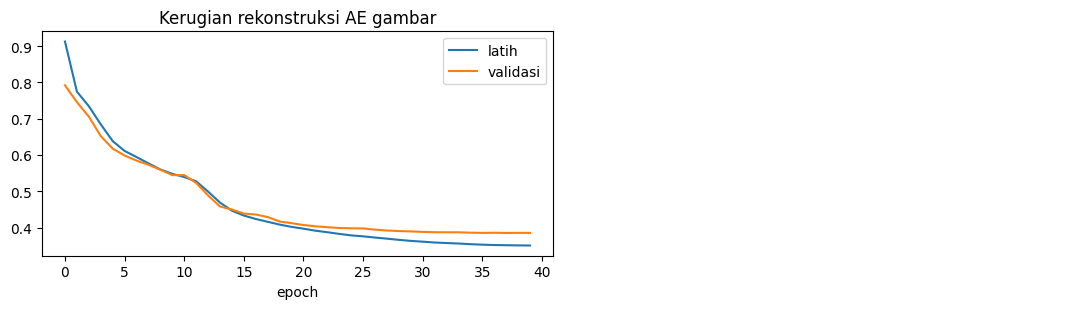

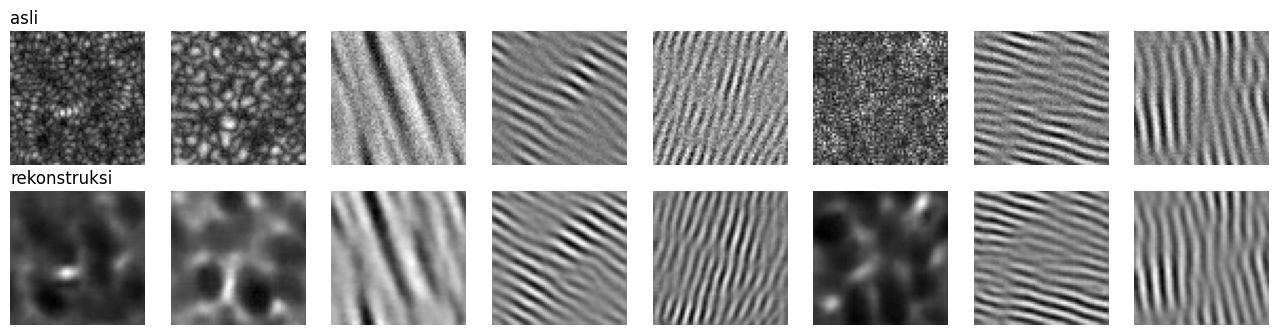

In [12]:
G = torch.from_numpy(gn).to(dev)
S = torch.from_numpy(sn).to(dev)
t0 = time.time()
ae_g = AEGambar(D_G).to(dev)
h_ae_g = latih(ae_g, [G], langkah_ae_gambar, EP_AE_G, BS, 1e-3, seed=SEED, nama='AE gambar')
ae_g.eval()
EMB['ae_gambar'] = ekstrak(lambda g: ae_g.enc(g.unsqueeze(1)), [G])
HASIL['ae_gambar'] = dict(loss_latih=h_ae_g[-1][0], loss_val=h_ae_g[-1][1], dim=D_G, waktu_dtk=time.time() - t0)
print(f"selesai {time.time() - t0:.0f} dtk | embedding {EMB['ae_gambar'].shape}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot([a for a, b in h_ae_g], label='latih'); ax[0].plot([b for a, b in h_ae_g], label='validasi')
ax[0].set_title("Kerugian rekonstruksi AE gambar"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].axis('off')
plt.tight_layout(); plt.show()

idx = np.random.RandomState(2).choice(len(gn), 8, replace=False)
with torch.no_grad():
    rec = ae_g(G[idx].unsqueeze(1)).squeeze(1).cpu().numpy()
fig, ax = plt.subplots(2, 8, figsize=(13, 3.4))
for c, i in enumerate(range(8)):
    ax[0, c].imshow(gn[idx[c]], cmap='gray'); ax[0, c].axis('off')
    ax[1, c].imshow(rec[c], cmap='gray'); ax[1, c].axis('off')
ax[0, 0].set_title("asli", loc='left'); ax[1, 0].set_title("rekonstruksi", loc='left')
plt.tight_layout(); plt.show()

  SimCLR ep 1/60: loss latih 5.7306 | validasi 5.6927
  SimCLR ep 10/60: loss latih 3.0140 | validasi 3.5207
  SimCLR ep 20/60: loss latih 2.7427 | validasi 3.2444
  SimCLR ep 30/60: loss latih 2.6266 | validasi 3.1421
  SimCLR ep 40/60: loss latih 2.5602 | validasi 3.0669
  SimCLR ep 50/60: loss latih 2.5240 | validasi 3.0387
  SimCLR ep 60/60: loss latih 2.5079 | validasi 3.0196


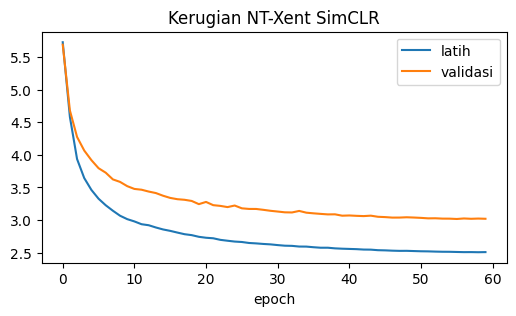

selesai 760 dtk | embedding (36000, 64)


In [13]:
if RUN_SIMCLR:
    t0 = time.time()
    sim = SimCLR(D_G).to(dev)
    h_sim = latih(sim, [G], langkah_simclr, EP_SIMCLR, BS_SIMCLR, 1e-3, seed=SEED, nama='SimCLR', cetak=10)
    sim.eval()
    EMB['simclr_gambar'] = ekstrak(lambda g: sim.enc(g.unsqueeze(1)), [G])
    HASIL['simclr_gambar'] = dict(loss_latih=h_sim[-1][0], loss_val=h_sim[-1][1], dim=D_G, waktu_dtk=time.time() - t0)
    plt.figure(figsize=(6, 3)); plt.plot([a for a, b in h_sim], label='latih'); plt.plot([b for a, b in h_sim], label='validasi')
    plt.title("Kerugian NT-Xent SimCLR"); plt.xlabel("epoch"); plt.legend(); plt.show()
    print(f"selesai {time.time() - t0:.0f} dtk | embedding {EMB['simclr_gambar'].shape}")

## 5. Encoder spektrum

*Autoencoder* MLP (128 → 256 → 128 → 32) dengan derau Gaussian pada masukan. Spektrum sudah distandarkan per fitur (dan per mikroskop bila diputuskan di bagian 2).

  AE spektrum ep 1/60: loss latih 0.9565 | validasi 0.7781
  AE spektrum ep 10/60: loss latih 0.1236 | validasi 0.1181
  AE spektrum ep 20/60: loss latih 0.0797 | validasi 0.0747
  AE spektrum ep 30/60: loss latih 0.0523 | validasi 0.0527
  AE spektrum ep 40/60: loss latih 0.0406 | validasi 0.0429
  AE spektrum ep 50/60: loss latih 0.0356 | validasi 0.0395
  AE spektrum ep 60/60: loss latih 0.0344 | validasi 0.0387
{'loss_latih': 0.0344, 'loss_val': 0.0387, 'dim': 32, 'waktu_dtk': 16.9045, 'mse_pca_sama_dim': 0.0735, 'mse_rekonstruksi_semua': 0.0324}


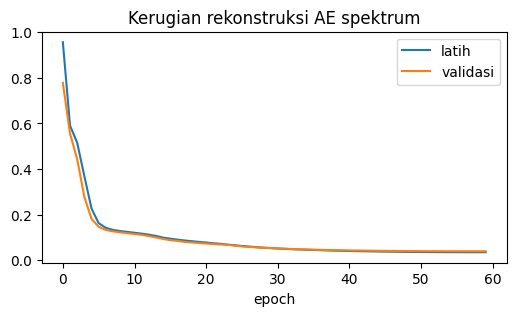

In [14]:
t0 = time.time()
ae_s = AESpektrum(D_S).to(dev)
h_ae_s = latih(ae_s, [S], langkah_ae_spektrum, EP_AE_S, BS, 1e-3, seed=SEED, nama='AE spektrum', cetak=10)
ae_s.eval()
EMB['ae_spektrum'] = ekstrak(lambda s: ae_s.enc(s), [S])
HASIL['ae_spektrum'] = dict(loss_latih=h_ae_s[-1][0], loss_val=h_ae_s[-1][1], dim=D_S, waktu_dtk=time.time() - t0)
# kerugian pembanding: PCA dengan jumlah dimensi sama
from sklearn.decomposition import PCA
p_s = PCA(D_S, random_state=SEED).fit(sn)
HASIL['ae_spektrum']['mse_pca_sama_dim'] = float(((sn - p_s.inverse_transform(p_s.transform(sn))) ** 2).mean())
with torch.no_grad():
    HASIL['ae_spektrum']['mse_rekonstruksi_semua'] = float(F.mse_loss(ae_s(S), S).item())
print({k: round(v, 4) for k, v in HASIL['ae_spektrum'].items()})
plt.figure(figsize=(6, 3)); plt.plot([a for a, b in h_ae_s], label='latih'); plt.plot([b for a, b in h_ae_s], label='validasi')
plt.title("Kerugian rekonstruksi AE spektrum"); plt.xlabel("epoch"); plt.legend(); plt.show()

## 6. Fusi dua modalitas

Dua cara penggabungan dibandingkan.

**6a. Penggabungan embedding (*concatenation*).** Embedding gambar dan spektrum masing-masing distandarkan per dimensi lalu dibagi akar jumlah dimensinya, sehingga kedua modalitas memiliki total varians sama dan tidak ada yang mendominasi jarak. Dibuat untuk embedding *autoencoder* dan untuk SimCLR.

**6b. *Autoencoder* gabungan.** Dua encoder menghasilkan fitur yang digabung (fusi tingkat fitur seperti pada Task 1) menjadi satu kode 64 dimensi, yang harus merekonstruksi **kedua** modalitas. Selama pelatihan, salah satu modalitas dimatikan secara acak pada 30% sampel (*modality dropout*) sehingga kode tidak bergantung pada satu modalitas saja.

  AE gabungan ep 1/40: loss latih 1.9102 | validasi 1.7895
  AE gabungan ep 5/40: loss latih 1.1996 | validasi 0.9989
  AE gabungan ep 10/40: loss latih 0.9456 | validasi 0.7872
  AE gabungan ep 15/40: loss latih 0.8920 | validasi 0.7302
  AE gabungan ep 20/40: loss latih 0.8462 | validasi 0.6794
  AE gabungan ep 25/40: loss latih 0.7819 | validasi 0.6093
  AE gabungan ep 30/40: loss latih 0.7497 | validasi 0.5862
  AE gabungan ep 35/40: loss latih 0.7375 | validasi 0.5767
  AE gabungan ep 40/40: loss latih 0.7317 | validasi 0.5744


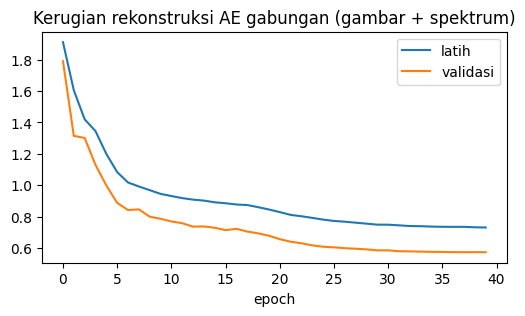

selesai 537 dtk
pca_gambar           (36000, 64)
pca_spektrum         (36000, 32)
pca_fusi             (36000, 96)
ae_gambar            (36000, 64)
simclr_gambar        (36000, 64)
ae_spektrum          (36000, 32)
fusi_ae_concat       (36000, 96)
fusi_simclr_concat   (36000, 96)
fusi_gabungan        (36000, 64)


In [15]:
EMB['fusi_ae_concat'] = fusi_concat(EMB['ae_gambar'], EMB['ae_spektrum'])
if 'simclr_gambar' in EMB:
    EMB['fusi_simclr_concat'] = fusi_concat(EMB['simclr_gambar'], EMB['ae_spektrum'])

t0 = time.time()
joint = AEGabungan(D_F).to(dev)
h_j = latih(joint, [G, S], langkah_gabungan, EP_JOINT, BS, 1e-3, seed=SEED, nama='AE gabungan')
joint.eval()
EMB['fusi_gabungan'] = ekstrak(lambda g, s: joint.encode(g.unsqueeze(1), s), [G, S])
HASIL['ae_gabungan'] = dict(loss_latih=h_j[-1][0], loss_val=h_j[-1][1], dim=D_F, waktu_dtk=time.time() - t0)
plt.figure(figsize=(6, 3)); plt.plot([a for a, b in h_j], label='latih'); plt.plot([b for a, b in h_j], label='validasi')
plt.title("Kerugian rekonstruksi AE gabungan (gambar + spektrum)"); plt.xlabel("epoch"); plt.legend(); plt.show()
print(f"selesai {time.time() - t0:.0f} dtk")
for k, v in EMB.items(): print(f"{k:20s} {v.shape}")

## 7. Pemeriksaan representasi tanpa label

Karena tidak ada label, embedding tidak dapat dinilai dengan akurasi kelas. Tiga pemeriksaan berikut hanya memberi petunjuk awal. Penilaian pengelompokan yang lebih lengkap dikerjakan pada tahap berikutnya.

1. **Mikroskop dapat ditebak?** Akurasi seimbang mendekati 0,5 berarti representasi tidak memuat efek alat (lebih baik). Representasi yang semua nilainya runtuh menjadi konstan juga memberi nilai rendah, jadi pemeriksaan ini selalu dibaca bersama pemeriksaan lain.
2. **Silhouette K-Means untuk k = 2 sampai 10** pada 5.000 sampel acak: seberapa jelas struktur kelompok. Nilai antar representasi berbeda geometri, jadi hanya dipakai sebagai petunjuk, bukan pemeringkat mutlak.
3. **Kesepakatan antar modalitas**: irisan 10 tetangga terdekat menurut embedding gambar dan menurut embedding spektrum, dibandingkan nilai kebetulan. Bila kedua modalitas memuat struktur bersama, irisan ini jauh di atas kebetulan, dan itu alasan yang masuk akal untuk menggabungkannya.

,representasi,dim,mikroskop_akurasi,mikroskop_seimbang,mayoritas,k_terbaik,silhouette
0,pca_gambar,64,0.507,0.504,0.601,2,0.319
1,pca_spektrum,32,0.493,0.489,0.601,2,0.260
2,pca_fusi,96,0.490,0.494,0.601,3,0.105
3,ae_gambar,64,0.495,0.496,0.601,4,0.122
4,simclr_gambar,64,0.944,0.944,0.601,2,0.361
5,ae_spektrum,32,0.496,0.494,0.601,7,0.132
6,fusi_ae_concat,96,0.495,0.494,0.601,2,0.096
7,fusi_simclr_concat,96,0.944,0.944,0.601,2,0.209
8,fusi_gabungan,64,0.538,0.546,0.601,5,0.146


,gambar,spektrum,tumpang,kebetulan
0,pca_gambar,pca_spektrum,0.0021,0.0017
1,ae_gambar,ae_spektrum,0.0042,0.0017
2,simclr_gambar,ae_spektrum,0.0065,0.0017


waktu 48 dtk


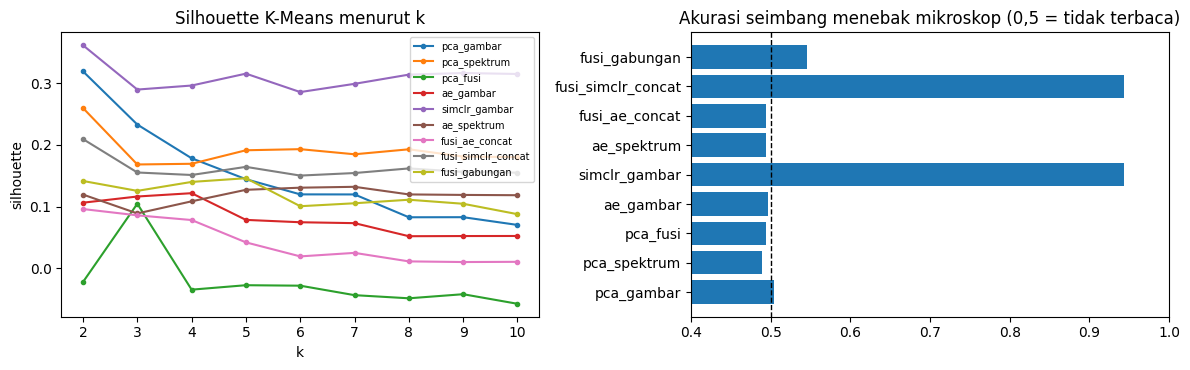

In [16]:
t0 = time.time()
baris, SIL = [], {}
for nama, e in EMB.items():
    p = probe_mikroskop(e, mik, seed=SEED)
    sil = silhouette_k(e, range(2, 11), seed=SEED)
    SIL[nama] = sil
    kb = max(sil, key=sil.get)
    baris.append(dict(representasi=nama, dim=e.shape[1], mikroskop_akurasi=p['akurasi'], mikroskop_seimbang=p['akurasi_seimbang'],
                      mayoritas=p['mayoritas'], k_terbaik=kb, silhouette=sil[kb]))
tab = pd.DataFrame(baris)
display(tab.round(3))
INFO['tabel'] = baris

pasangan = [('pca_gambar', 'pca_spektrum'), ('ae_gambar', 'ae_spektrum')]
if 'simclr_gambar' in EMB: pasangan.append(('simclr_gambar', 'ae_spektrum'))
sil_antar = []
for a, b in pasangan:
    r = tumpang_knn(EMB[a], EMB[b], seed=SEED)
    sil_antar.append(dict(gambar=a, spektrum=b, **r))
tab2 = pd.DataFrame(sil_antar)
display(tab2.round(4))
INFO['silang'] = sil_antar
print(f"waktu {time.time() - t0:.0f} dtk")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for nama, sil in SIL.items():
    ax[0].plot(list(sil.keys()), list(sil.values()), marker='o', ms=3, label=nama)
ax[0].set_xlabel("k"); ax[0].set_ylabel("silhouette"); ax[0].set_title("Silhouette K-Means menurut k"); ax[0].legend(fontsize=7)
ax[1].barh(tab.representasi, tab.mikroskop_seimbang); ax[1].axvline(0.5, color='k', ls='--', lw=1)
ax[1].set_xlim(0.4, 1.0); ax[1].set_title("Akurasi seimbang menebak mikroskop (0,5 = tidak terbaca)")
plt.tight_layout(); plt.show()

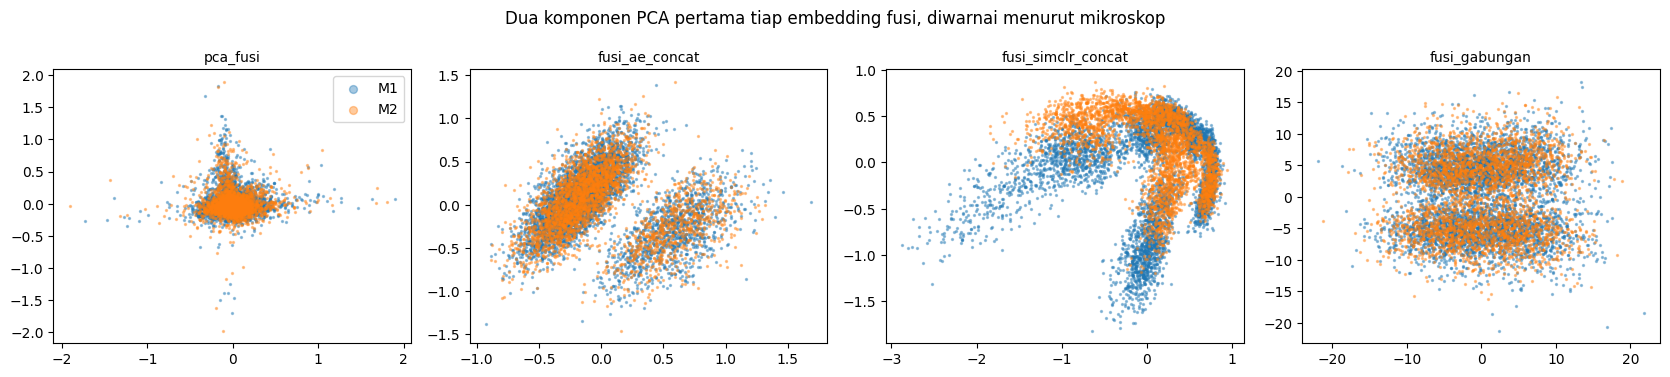

In [17]:
from sklearn.decomposition import PCA
nama_plot = [n for n in ['pca_fusi', 'fusi_ae_concat', 'fusi_simclr_concat', 'fusi_gabungan'] if n in EMB]
fig, ax = plt.subplots(1, len(nama_plot), figsize=(4.2 * len(nama_plot), 3.8))
ax = np.atleast_1d(ax)
rs = np.random.RandomState(0).choice(len(mik), 8000, replace=False)
for a, n in zip(ax, nama_plot):
    z = PCA(2, random_state=0).fit_transform(EMB[n][rs])
    for m in sorted(np.unique(mik)):
        i = mik[rs] == m
        a.scatter(z[i, 0], z[i, 1], s=2, alpha=0.4, label=m)
    a.set_title(n, fontsize=10)
ax[0].legend(markerscale=4)
plt.suptitle("Dua komponen PCA pertama tiap embedding fusi, diwarnai menurut mikroskop"); plt.tight_layout(); plt.show()

## 8. Penyimpanan dan serah-terima

Seluruh embedding disimpan sebagai `float16` berukuran (36.000 × dimensi) dengan **urutan baris sama persis seperti `clustering.npz` dan `clustering_meta.csv`**. Bobot encoder disimpan agar embedding dapat direproduksi tanpa melatih ulang. Berkas `manifest.json` mencatat pengaturan yang dipakai.

In [18]:
EMB_DIR = f'{OUT}/emb'
for f in os.listdir(EMB_DIR):
    if f.endswith('.npy'): os.remove(f'{EMB_DIR}/{f}')
for nama, e in EMB.items():
    simpan_emb(EMB_DIR, nama, e)

torch.save(ae_g.enc.state_dict(), f'{OUT}/bobot/enc_ae_gambar.pt')
torch.save(ae_s.enc.state_dict(), f'{OUT}/bobot/enc_ae_spektrum.pt')
torch.save({'eg': joint.eg.state_dict(), 'es': joint.es.state_dict(), 'fuse': joint.fuse.state_dict()}, f'{OUT}/bobot/enc_gabungan.pt')
if 'simclr_gambar' in EMB:
    torch.save(sim.enc.state_dict(), f'{OUT}/bobot/enc_simclr_gambar.pt')

manifest = dict(urutan_baris='sama dengan clustering.npz dan clustering_meta.csv', n=int(len(mik)), tipe_simpan='float16',
                embedding={k: list(v.shape) for k, v in EMB.items()}, seed=SEED,
                normalisasi_per_mikroskop=NORM_PER_MIK,
                hiperparameter=dict(D_G=D_G, D_S=D_S, D_F=D_F, EP_AE_G=EP_AE_G, EP_SIMCLR=EP_SIMCLR, EP_AE_S=EP_AE_S, EP_JOINT=EP_JOINT,
                                    BS=BS, BS_SIMCLR=BS_SIMCLR),
                versi=dict(python=sys.version.split()[0], torch=torch.__version__, numpy=numpy.__version__, sklearn=sklearn.__version__))
with open(f'{EMB_DIR}/manifest.json', 'w') as f: json.dump(manifest, f, indent=2)
with open(f'{OUT}/hasil/task3_representasi.json', 'w') as f: json.dump({'info': INFO, 'hasil': HASIL}, f, indent=2, default=float)
!du -sh {EMB_DIR} {OUT}/bobot
!ls -la {EMB_DIR}

42M	/content/UTSDEEPLEARNING/kode/task3_cluster/emb
19M	/content/UTSDEEPLEARNING/kode/task3_cluster/bobot
total 42788
drwxr-xr-x 2 root root    4096 Nov 22 16:57 .
drwxr-xr-x 6 root root    4096 Nov 22 16:24 ..
-rw-r--r-- 1 root root 4608128 Nov 22 16:57 ae_gambar.npy
-rw-r--r-- 1 root root 2304128 Nov 22 16:57 ae_spektrum.npy
-rw-r--r-- 1 root root 6912128 Nov 22 16:57 fusi_ae_concat.npy
-rw-r--r-- 1 root root 4608128 Nov 22 16:57 fusi_gabungan.npy
-rw-r--r-- 1 root root 6912128 Nov 22 16:57 fusi_simclr_concat.npy
-rw-r--r-- 1 root root     950 Nov 22 16:57 manifest.json
-rw-r--r-- 1 root root 6912128 Nov 22 16:57 pca_fusi.npy
-rw-r--r-- 1 root root 4608128 Nov 22 16:57 pca_gambar.npy
-rw-r--r-- 1 root root 2304128 Nov 22 16:57 pca_spektrum.npy
-rw-r--r-- 1 root root 4608128 Nov 22 16:57 simclr_gambar.npy


## 9. Kesimpulan tahap 1

Teks di bawah dibangkitkan otomatis dari hasil yang tercatat pada notebook ini, sehingga angka dan arah temuan mengikuti keluaran yang sebenarnya.

In [19]:
def _f(x, n=2): return f"{x:.{n}f}".replace('.', ',')

def buat_kesimpulan_t3a(info, hasil):
    d, m, tab, sil = info['data'], info['mikroskop'], info['tabel'], info['silang']
    jm = ', '.join(f"{k}: {v}" for k, v in d['jumlah_mikroskop'].items())
    p = []
    p.append(f"**1. Data.** Terdapat {d['n']} sampel dengan citra {d['bentuk_gambar'][1]}×{d['bentuk_gambar'][2]} dan spektrum {d['bentuk_spektrum'][1]} dimensi. "
             f"Jumlah per mikroskop: {jm}. Nilai spektrum yang hilang atau tidak hingga: {d['spektrum_nan']} sel (diisi median per fitur: {info.get('spektrum_diisi', 0)}). "
             f"ID sampel {'unik' if d['id_unik'] else 'tidak unik'}.")
    gl = [r for r in m['tabel'] if r['normalisasi'] == 'global']
    pm = [r for r in m['tabel'] if r['normalisasi'] == 'per mikroskop']
    t = ', '.join(f"{r['modalitas']} {_f(r['akurasi_seimbang'])}" for r in gl)
    t2 = ', '.join(f"{r['modalitas']} {_f(r['akurasi_seimbang'])}" for r in pm)
    kal = ("Karena mikroskop dapat ditebak dari fitur mentah, normalisasi dilakukan per mikroskop." if m['per_mikroskop_dipakai']
           else "Mikroskop tidak terbaca jelas dari fitur mentah, sehingga dipakai normalisasi global.")
    p.append(f"**2. Efek mikroskop.** Akurasi seimbang menebak mikroskop dari fitur mentah dengan normalisasi global: {t}; dengan normalisasi per mikroskop: {t2} (0,5 berarti tidak terbaca). {kal} "
             "Asumsinya, perbedaan antar mikroskop adalah efek alat dan bukan perbedaan komposisi material; bila asumsi ini keliru, sebagian struktur nyata ikut terhapus.")
    rec = []
    for k in ['ae_gambar', 'ae_spektrum', 'ae_gabungan']:
        if k in hasil: rec.append(f"{k} (validasi {_f(hasil[k]['loss_val'], 3)})")
    extra = ''
    if 'mse_pca_sama_dim' in hasil.get('ae_spektrum', {}):
        a = hasil['ae_spektrum']
        extra = f" Untuk spektrum, galat rekonstruksi semua sampel {_f(a['mse_rekonstruksi_semua'], 3)} dibanding {_f(a['mse_pca_sama_dim'], 3)} untuk PCA berdimensi sama."
    p.append("**3. Representasi.** Model yang dilatih tanpa label: " + ', '.join(rec) + (", dan SimCLR untuk gambar" if 'simclr_gambar' in hasil else "") + f".{extra}")
    best_mik = min(tab, key=lambda r: r['mikroskop_seimbang'])
    best_sil = max(tab, key=lambda r: r['silhouette'])
    tinggi = [r['representasi'] for r in tab if r['mikroskop_seimbang'] > 0.6]
    ket = (f" Representasi yang mikroskopnya masih mudah ditebak (akurasi seimbang di atas 0,60): {', '.join(tinggi)}." if tinggi
           else " Tidak ada representasi yang mikroskopnya mudah ditebak (semua akurasi seimbang tidak lebih dari 0,60).")
    p.append(f"**4. Pemeriksaan tanpa label.** Akurasi seimbang menebak mikroskop paling rendah pada {best_mik['representasi']} ({_f(best_mik['mikroskop_seimbang'])}). "
             f"Silhouette K-Means tertinggi pada {best_sil['representasi']} ({_f(best_sil['silhouette'])} pada k = {best_sil['k_terbaik']}); angka ini hanya petunjuk karena geometri tiap representasi berbeda.{ket}")
    ss = '; '.join(f"{r['gambar']} dengan {r['spektrum']}: {_f(r['tumpang'], 3)} (kebetulan {_f(r['kebetulan'], 3)})" for r in sil)
    rasio = min(r['tumpang'] / r['kebetulan'] for r in sil)
    kes5 = (f"Semua irisan lebih dari {_f(rasio, 0)} kali nilai kebetulan, sehingga kedua modalitas memuat struktur yang sebagian sama; seberapa jauh itu mendukung fusi dinilai pada tahap pengelompokan."
            if rasio > 3 else "Irisan hanya sedikit di atas nilai kebetulan pada sedikitnya satu pasangan, sehingga bukti bahwa kedua modalitas memuat struktur bersama lemah; ini perlu diperhatikan pada tahap pengelompokan.")
    p.append(f"**5. Kesepakatan antar modalitas.** Irisan 10 tetangga terdekat: {ss}. {kes5}")
    p.append("**6. Keterbatasan.** Tidak ada label, sehingga representasi hanya diperiksa lewat petunjuk tidak langsung; pemilihan akhir dilakukan pada tahap pengelompokan. Satu seed dan hiperparameter belum disetel. SimCLR mengandaikan bahwa rotasi kecil dan cermin tidak mengubah identitas material. "
             "Normalisasi per mikroskop mengandaikan bahwa perbedaan alat dapat dipisahkan dari perbedaan material.")
    p.append("**7. Serah-terima.** Embedding `float16` berurutan sama dengan `clustering.npz` tersedia di `kode/task3_cluster/emb/` beserta `manifest.json`. Tahap berikutnya membandingkan K-Means, GMM, dan agglomerative pada semua representasi, memilih jumlah klaster dengan beberapa kriteria, dan menilai kemandirian klaster terhadap mikroskop.")
    return '\n\n'.join(p)

from IPython.display import Markdown, display
KESIMPULAN = buat_kesimpulan_t3a(INFO, HASIL)
display(Markdown(KESIMPULAN))

**1. Data.** Terdapat 36000 sampel dengan citra 64×64 dan spektrum 128 dimensi. Jumlah per mikroskop: M1: 21636, M2: 14364. Nilai spektrum yang hilang atau tidak hingga: 0 sel (diisi median per fitur: 0). ID sampel unik.

**2. Efek mikroskop.** Akurasi seimbang menebak mikroskop dari fitur mentah dengan normalisasi global: gambar 0,79, spektrum 0,49; dengan normalisasi per mikroskop: gambar 0,50, spektrum 0,49 (0,5 berarti tidak terbaca). Karena mikroskop dapat ditebak dari fitur mentah, normalisasi dilakukan per mikroskop. Asumsinya, perbedaan antar mikroskop adalah efek alat dan bukan perbedaan komposisi material; bila asumsi ini keliru, sebagian struktur nyata ikut terhapus.

**3. Representasi.** Model yang dilatih tanpa label: ae_gambar (validasi 0,385), ae_spektrum (validasi 0,039), ae_gabungan (validasi 0,574), dan SimCLR untuk gambar. Untuk spektrum, galat rekonstruksi semua sampel 0,032 dibanding 0,074 untuk PCA berdimensi sama.

**4. Pemeriksaan tanpa label.** Akurasi seimbang menebak mikroskop paling rendah pada pca_spektrum (0,49). Silhouette K-Means tertinggi pada simclr_gambar (0,36 pada k = 2); angka ini hanya petunjuk karena geometri tiap representasi berbeda. Representasi yang mikroskopnya masih mudah ditebak (akurasi seimbang di atas 0,60): simclr_gambar, fusi_simclr_concat.

**5. Kesepakatan antar modalitas.** Irisan 10 tetangga terdekat: pca_gambar dengan pca_spektrum: 0,002 (kebetulan 0,002); ae_gambar dengan ae_spektrum: 0,004 (kebetulan 0,002); simclr_gambar dengan ae_spektrum: 0,006 (kebetulan 0,002). Irisan hanya sedikit di atas nilai kebetulan pada sedikitnya satu pasangan, sehingga bukti bahwa kedua modalitas memuat struktur bersama lemah; ini perlu diperhatikan pada tahap pengelompokan.

**6. Keterbatasan.** Tidak ada label, sehingga representasi hanya diperiksa lewat petunjuk tidak langsung; pemilihan akhir dilakukan pada tahap pengelompokan. Satu seed dan hiperparameter belum disetel. SimCLR mengandaikan bahwa rotasi kecil dan cermin tidak mengubah identitas material. Normalisasi per mikroskop mengandaikan bahwa perbedaan alat dapat dipisahkan dari perbedaan material.

**7. Serah-terima.** Embedding `float16` berurutan sama dengan `clustering.npz` tersedia di `kode/task3_cluster/emb/` beserta `manifest.json`. Tahap berikutnya membandingkan K-Means, GMM, dan agglomerative pada semua representasi, memilih jumlah klaster dengan beberapa kriteria, dan menilai kemandirian klaster terhadap mikroskop.

## 10. Commit ke branch `task3-representasi`

Kode, embedding, bobot encoder, dan ringkasan hasil di-commit. Setelah sel ini, simpan notebook dengan **File → Save a copy in GitHub** (repositori fork, branch `task3-representasi`, path `kode/task3_cluster/task3_representasi.ipynb`), lalu buka *pull request* ke repositori organisasi.

In [20]:
with open(f'{OUT}/hasil/kesimpulan_task3_representasi.md', 'w') as f: f.write(KESIMPULAN)
%cd /content/UTSDEEPLEARNING
!git add kode/task3_cluster/clu_data.py kode/task3_cluster/clu_model.py kode/task3_cluster/hasil kode/task3_cluster/emb kode/task3_cluster/bobot
!git commit -m "Task 3 tahap 1: representasi tanpa label (AE, SimCLR), fusi, embedding untuk tahap pengelompokan"
!git push origin task3-representasi

/content/UTSDEEPLEARNING
[task3-representasi a483427] Task 3 tahap 1: representasi tanpa label (AE, SimCLR), fusi, embedding untuk tahap pengelompokan
 18 files changed, 600 insertions(+)
 create mode 100644 kode/task3_cluster/bobot/enc_ae_gambar.pt
 create mode 100644 kode/task3_cluster/bobot/enc_ae_spektrum.pt
 create mode 100644 kode/task3_cluster/bobot/enc_gabungan.pt
 create mode 100644 kode/task3_cluster/bobot/enc_simclr_gambar.pt
 create mode 100644 kode/task3_cluster/clu_data.py
 create mode 100644 kode/task3_cluster/clu_model.py
 create mode 100644 kode/task3_cluster/emb/ae_gambar.npy
 create mode 100644 kode/task3_cluster/emb/ae_spektrum.npy
 create mode 100644 kode/task3_cluster/emb/fusi_ae_concat.npy
 create mode 100644 kode/task3_cluster/emb/fusi_gabungan.npy
 create mode 100644 kode/task3_cluster/emb/fusi_simclr_concat.npy
 create mode 100644 kode/task3_cluster/emb/manifest.json
 create mode 100644 kode/task3_cluster/emb/pca_fusi.npy
 create mode 100644 kode/task3_cluster